# ЛР 07. Категориальные признаки в задаче оценки цены автомобиля


## 1. Загрузка и разбиение данных

Используем те же признаки и то же разбиение, что в ЛР 06: 60% для обучения, 20% для сравнения вариантов и 20% для итоговой проверки. До разбиения ничего не кодируем и не масштабируем.

In [1]:
# Если библиотек нет, раскомментируйте строку и перезапустите ядро.
# %pip install "scikit-learn>=1.4" pandas numpy scipy matplotlib lightgbm catboost
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
data_path = Path('cars_processed.csv')
if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
        'refs/heads/main/Workshops/cars_processed.csv'
    )

In [3]:
df = df.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')].reset_index(drop=True)
print(df.shape)
display(df.head())

(32067, 11)


,Make,Model,Year,Style,Distance,Engine,Fuel_type,AutoTransmission,Price,Age,km_year
0,Toyota,Prius,2011,Hatchback,195000.0,1800.0,Hybrid,True,7750.0,11,17727.272727
1,Renault,Grand Scenic,2014,Universal,135000.0,1500.0,Diesel,False,8550.0,8,16875.000000
2,Renault,Laguna,2012,Universal,110000.0,1500.0,Diesel,False,6550.0,10,11000.000000
3,Opel,Astra,2006,Universal,200000.0,1600.0,Metan/Propan,False,4100.0,16,12500.000000
4,Mercedes,Vito,2000,Microvan,300000.0,2200.0,Diesel,False,3490.0,22,13636.363636


In [4]:
y = df['Price']
X = df.drop(columns=['Price', 'Age'])

from sklearn.model_selection import train_test_split

X_train, X_holdout, y_train, y_holdout = train_test_split(
                                                X, y, test_size=0.4, random_state=42
                                            )
X_valid, X_test, y_valid, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=43
)
print('Train, validation, test:', len(X_train), len(X_valid), len(X_test))

Train, validation, test: 19240 6413 6414


`Age` исключаем как дубликат информации из `Year`. Типы признаков определяем по обучающей выборке.

In [5]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

print('Числовые:', num_cols)
print('Категориальные:', cat_cols)

Числовые: ['Year', 'Distance', 'Engine', 'km_year']
Категориальные: ['Make', 'Model', 'Style', 'Fuel_type', 'AutoTransmission']


## 2. Кодируем тип трансмиссии: 1 — автоматическая, 0 — механическая

Применяем один и тот же словарь ко всем частям. Исходный столбец `AutoTransmission` содержит `True` и `False`. Новый столбец с текстовыми названиями не нужен.

In [6]:
auto_map = {True: 1, False: 0}
X_train['AutoTransmission'] = X_train['AutoTransmission'].map(auto_map)
X_valid['AutoTransmission'] = X_valid['AutoTransmission'].map(auto_map)
X_test['AutoTransmission']  = X_test['AutoTransmission'].map(auto_map)

display(X_train['AutoTransmission'].value_counts().sort_index())

AutoTransmission
0    10443
1     8797
Name: count, dtype: int64

### LR и RF с типом трансмиссии и без него

Для каждого алгоритма меняем только набор признаков. Сравниваем MAE и RMSE на validation, обе метрики в евро.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

In [8]:
num_auto_cols = num_cols + ['AutoTransmission']

#### Linear Regression

In [9]:
lr = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])

In [16]:
baseline_rows = []

for cols, label in [(num_cols,      'Без типа трансмиссии'), 
                    (num_auto_cols, 'С типом трансмиссии')]:
    
    lr.fit(X_train[cols], y_train)
    pred = lr.predict(X_valid[cols])
    
    print(f'{label}\tMAE\t{mean_absolute_error(y_valid, pred):.2f}\tRMSE\t{root_mean_squared_error(y_valid, pred):.2f}' )

Без типа трансмиссии	MAE	4307.77	RMSE	7685.15
С типом трансмиссии	MAE	4177.20	RMSE	7584.74


#### Random Foreset

In [17]:
rf_params = dict(n_estimators=10, max_depth=10)

rf = RandomForestRegressor(**rf_params)

In [18]:
baseline_rows = []

for cols, label in [(num_cols,      'Без типа трансмиссии'), 
                    (num_auto_cols, 'С типом трансмиссии')]:
    
    rf.fit(X_train[cols], y_train)
    pred = rf.predict(X_valid[cols])

    print(f'{label}\tMAE\t{mean_absolute_error(y_valid, pred):.2f}\tRMSE\t{root_mean_squared_error(y_valid, pred):.2f}' )

Без типа трансмиссии	MAE	2646.91	RMSE	5689.53
С типом трансмиссии	MAE	2589.80	RMSE	5638.29


Видно, что на линейной регрессии включение признака сказалось сильнее, чем на RF. 

### Дерево глубины 3 с типом трансмиссии

Используем числа и `AutoTransmission`. Разбиение `AutoTransmission ≤ 0.5` отделяет механическую трансмиссию (0) от автоматической (1). На этом дереве такое разбиение есть.

In [19]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X_train[num_auto_cols], y_train)
tree_pred = tree.predict(X_valid[num_auto_cols])
print(f'MAE дерева на validation: {mean_absolute_error(y_valid, tree_pred):.2f}')

MAE дерева на validation: 3527.34


In [20]:
dt = DecisionTreeRegressor(max_depth=10, random_state=42)

In [22]:
baseline_rows = []

for cols, label in [(num_cols,      'Без типа трансмиссии'), 
                    (num_auto_cols, 'С типом трансмиссии')]:
    
    dt.fit(X_train[cols], y_train)
    pred = dt.predict(X_valid[cols])

    print(f'{label}\tMAE\t{mean_absolute_error(y_valid, pred):.2f}\tRMSE\t{root_mean_squared_error(y_valid, pred):.2f}' )

Без типа трансмиссии	MAE	2759.08	RMSE	6135.44
С типом трансмиссии	MAE	2707.58	RMSE	6037.67


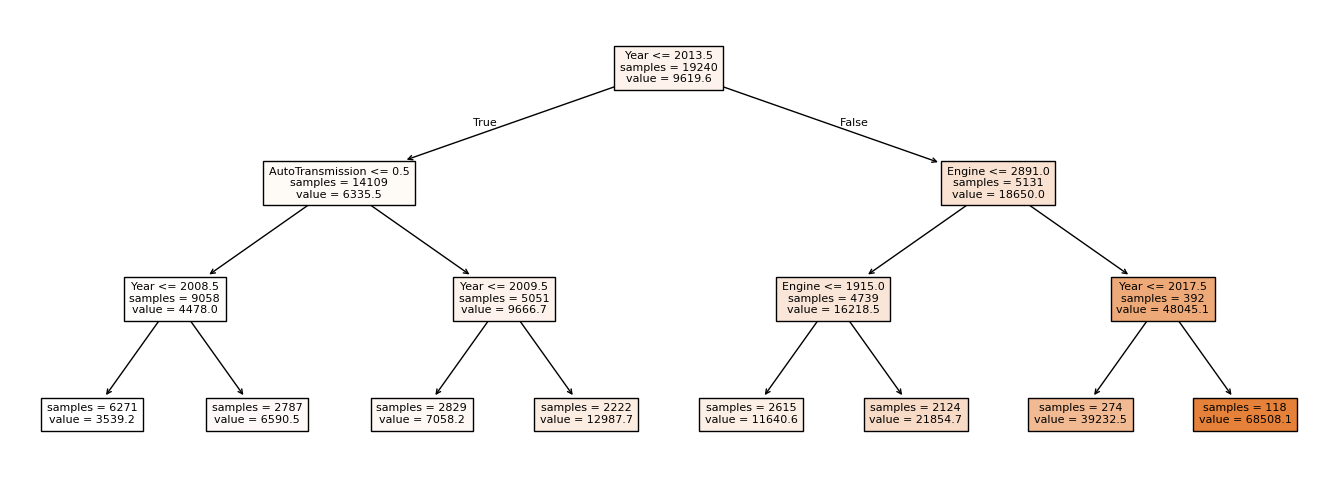

In [23]:
tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X_train[num_auto_cols], y_train)

plt.figure(figsize=(17, 6))
plot_tree(tree, feature_names=num_auto_cols, filled=True,
          impurity=False, precision=1, fontsize=8)
plt.show()

Видно, что тип трансмиссии влияет на работу дерева. На сколько цепочка правил верная следует уточнить у автоэксперта.

#### важность признаков

Дополнительно проверим эффект запросив оценку важности признаков.

`feature_importances_` показывает вклад признаков в уменьшение квадратичной ошибки при разбиениях, усреднённый по деревьям леса. Чем больше значение, тем чаще или сильнее признак уменьшал ошибку при разбиениях.

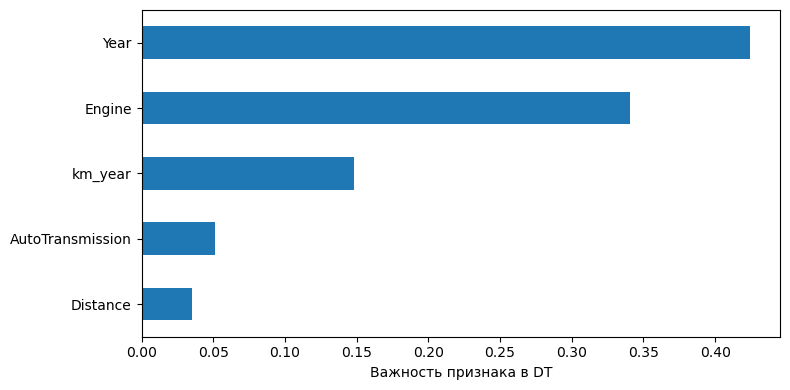

In [24]:
importance = pd.Series(dt.feature_importances_, index=X_train[cols].columns)
importance = importance.sort_values(ascending=False)
importance.iloc[::-1].plot.barh(figsize=(8, 4), xlabel='Важность признака в DT')
plt.tight_layout()
plt.show()

#### Упражнение
1. Проверьте гипотезу о том, что удаление столбца "Пробег в год" повысит важность признака "Пробег"

In [42]:
num_auto_cols = [x for x in num_auto_cols if x != 'km_year']
num_auto_cols

['Year', 'Distance', 'Engine', 'AutoTransmission']

In [43]:
baseline_rows = []

for  reg in [lr, dt, rf]:
    print(reg)
    for cols, label in [(num_cols,      'Без типа трансмиссии'), 
                        (num_auto_cols, 'С типом трансмиссии')]:
        
        reg.fit(X_train[cols], y_train)
        pred = reg.predict(X_valid[cols])
    
        print(f'{label}\tMAE\t{mean_absolute_error(y_valid, pred):.2f}\tRMSE\t{root_mean_squared_error(y_valid, pred):.2f}' )

Pipeline(steps=[('scale', StandardScaler()), ('model', LinearRegression())])
Без типа трансмиссии	MAE	4307.77	RMSE	7685.15
С типом трансмиссии	MAE	4197.25	RMSE	7593.25
DecisionTreeRegressor(max_depth=10, random_state=42)
Без типа трансмиссии	MAE	2759.08	RMSE	6135.44
С типом трансмиссии	MAE	2692.90	RMSE	5988.90
RandomForestRegressor(max_depth=10, n_estimators=10)
Без типа трансмиссии	MAE	2647.15	RMSE	5703.42
С типом трансмиссии	MAE	2571.78	RMSE	5663.24


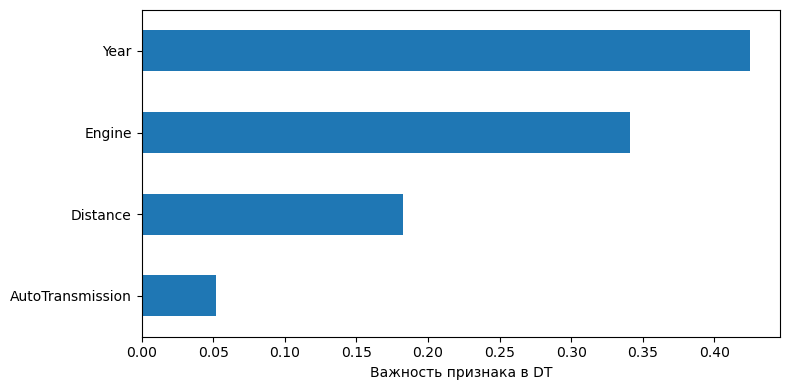

In [44]:
dt.fit(X_train[num_auto_cols], y_train)

importance = pd.Series(dt.feature_importances_, index=X_train[num_auto_cols].columns)
importance = importance.sort_values(ascending=False)
importance.iloc[::-1].plot.barh(figsize=(8, 4), xlabel='Важность признака в DT')
plt.tight_layout()
plt.show()

2. Проверьте как эффект сказывается на `Random Forest`

####  Ordinal Encoder: целочисленное кодирование текстовых признаков


Каждому названию можно назначить целый код. Дерево использует условия вида `код ≤ порог`: значение кода влияет на то, какие категории попадут в одну ветвь. Это произвольный порядок, поэтому результат может зависеть от нумерации.

In [45]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

train_all = X_train.copy()
valid_all = X_valid.copy()

train_all[cat_cols] = enc.fit_transform(X_train[cat_cols]).astype(int)
valid_all[cat_cols] = enc.transform(X_valid[cat_cols]).astype(int)

rf_all = RandomForestRegressor(**rf_params)

In [46]:
train_all

,Make,Model,Year,Style,Distance,Engine,Fuel_type,AutoTransmission,km_year
22222,18,222,2007,4,187000.0,1400.0,0,1,12466.666667
3091,20,325,2014,4,30500.0,2000.0,4,1,3812.500000
24316,10,678,2009,6,244140.0,2200.0,0,0,18780.000000
22327,9,75,1992,10,248600.0,1998.0,4,0,8286.666667
13572,17,620,2018,10,109000.0,2000.0,0,1,27250.000000
...,...,...,...,...,...,...,...,...,...
29802,20,649,2001,6,273685.0,2499.0,0,0,13032.619048
5390,6,719,2015,3,176800.0,2000.0,0,1,25257.142857
860,0,512,2018,9,17700.0,2995.0,4,1,4425.000000
15795,17,620,2017,4,92000.0,2000.0,0,1,18400.000000


In [51]:
rf_all.fit(train_all, y_train)

pred_rf_all_valid = rf_all.predict(valid_all)
mae_rf_all = mean_absolute_error(y_valid, pred_rf_all_valid)
rmse_rf_all = root_mean_squared_error(y_valid, pred_rf_all_valid)

print(f'RF MAE :\t{mae_rf_all:.2f}')
print(f'RF RMSE:\t{rmse_rf_all:.2f}')


RF MAE :	2240.69
RF RMSE:	5448.53


#### Упражнение
1. Проверьте метрики на тестовой части для всех алгоритмов 
* `LR`, `DT`, `RF` c трансмиссей, 
* `DT`, `RF` со всеми признаками пространственно-закодированными 

2. Проверьте важность признаков в DT и RF

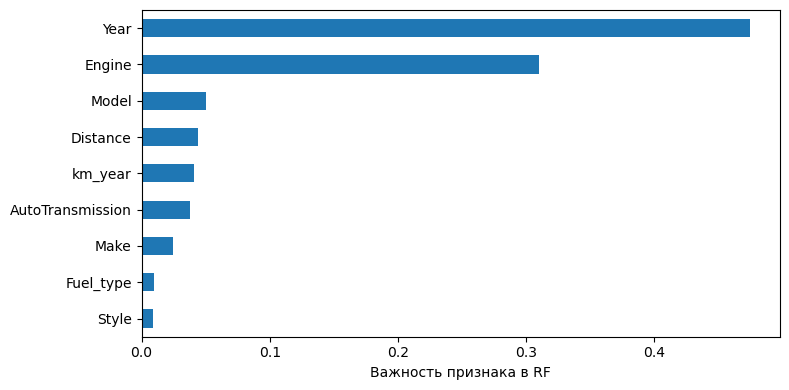

In [52]:
importance = pd.Series(rf_all.feature_importances_, index=train_all.columns)
importance = importance.sort_values(ascending=False)
importance.iloc[::-1].plot.barh(figsize=(8, 4), xlabel='Важность признака в RF')
plt.tight_layout()
plt.show()

Важность не всегда показывает действительную важность. Сильное связанные признаки могут мешать.

3. Мы когда-то вводили признак __"Пробег в год"__. Признак нужен был для фильтрации данных. Однако, признак связан со столбцами __"Пробег"__ и __"Год"__. Проверьте, как виляет удаление этого признака на точность `RF` и на важность признаков.


4. Мы проверили алгоритмы `LR`,`DT`,`RF`,  но не проверили `KNN`. Сдейлайте это самостоятельно

5.  Сокращение набора признаков RF
Мы можем предположить, глядя на график важности признаков, что действительно, тип кузова и тип двиготеля не так важны если известны марка и модель автомобиля. Проверим на сколько меняются результаты если эти признаки убрать.

Убираем от одного до трёх признаков с наименьшей важностью. На validation выбираем самый короткий набор, у которого и MAE, и RMSE выросли не более чем на 2% относительно полного набора. Это учебный допуск. Test при выборе не используем.

In [56]:
def evaluate_rf(cols, label, dropped=None):
    rf = RandomForestRegressor(**rf_params)
    rf.fit(train_all[cols], y_train)
    pred = rf.predict(valid_all[cols])
    return {
        'Вариант': label,
        'Исключены': ', '.join(dropped) if dropped else '—',
        'Признаков': len(cols),
        'MAE': mean_absolute_error(y_valid, pred),
        'RMSE': root_mean_squared_error(y_valid, pred),
    }

reduced_cols = train_all.columns.tolist()

results = pd.DataFrame([evaluate_rf(reduced_cols, 'все признаки')])
results = pd.concat(
    [results, pd.DataFrame(
        [evaluate_rf(importance.index[:-n],
                     f'без {n} последних',
                     dropped=importance.index[-n:].tolist())
         for n in [1, 2, 3]])],
    ignore_index=True,
)
results['Изменение MAE, %'] = 100 * results['MAE'] / results['MAE'].iloc[0] - 100
results['Изменение RMSE, %'] = 100 * results['RMSE'] / results['RMSE'].iloc[0] - 100
display(results.round(2))


,Вариант,Исключены,Признаков,MAE,RMSE,"Изменение MAE, %","Изменение RMSE, %"
0,все признаки,—,9,2247.99,5401.38,0.00,0.00
1,без 1 последних,Style,8,2253.38,5423.85,0.24,0.42
2,без 2 последних,"Fuel_type, Style",7,2252.88,5291.59,0.22,-2.03
3,без 3 последних,"Make, Fuel_type, Style",6,2355.52,5544.31,4.78,2.65


Проверьте выполнимость гипотезы о том, что тип кузова и тип топлева не нужны для LR, а также путем k-folds либо иным путем нескольких различающихся экспериментов.

6. Проверьте гипотезу о том, что марка и модель скоррелированны и лучше их объеденить в единую категорию __"Марка+Модель"__ и проверьте разные типы кодирования для этой гипотезы

## 4. LR: One-Hot Encoding

Если передать марку как число, LR умножит её код на один коэффициент. Тогда переход от кода 1 к 2 изменит прогноз на ту же величину, что переход от 2 к 3. Для названий марок такое ограничение не обосновано.

__One-Hot Encoding (OHE)__ создаёт отдельный индикатор для каждой категории. Тип трансмиссии уже задан одним индикатором 0/1.

Столбцы для validation и test выравниваем по именам столбцов train. Неизвестная категория не получает отдельного столбца: все её индикаторы из train равны нулю.

In [58]:
train_ohe = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
valid_ohe = pd.get_dummies(X_valid, columns=cat_cols, dtype=int)
test_ohe  = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
valid_ohe = valid_ohe.reindex(columns=train_ohe.columns, fill_value=0)
test_ohe  = test_ohe.reindex(columns=train_ohe.columns, fill_value=0)
print(f'Столбцов до OHE: {X_train.shape[1]} | После OHE: {train_ohe.shape[1]}')


Столбцов до OHE: 9 | После OHE: 769


In [59]:
display(train_ohe.iloc[:5, :12])

,Year,Distance,Engine,km_year,Make_Audi,Make_BMW,Make_Chevrolet,Make_Dacia,Make_Ford,Make_Honda,Make_Hyundai,Make_KIA
22222,2007,187000.0,1400.0,12466.666667,0,0,0,0,0,0,0,0
3091,2014,30500.0,2000.0,3812.500000,0,0,0,0,0,0,0,0
24316,2009,244140.0,2200.0,18780.000000,0,0,0,0,0,0,0,0
22327,1992,248600.0,1998.0,8286.666667,0,0,0,0,0,0,0,0
13572,2018,109000.0,2000.0,27250.000000,0,0,0,0,0,0,0,0


In [61]:
lr_ohe = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])

lr_ohe.fit(train_ohe, y_train)
pred_ohe_valid = lr_ohe.predict(valid_ohe)
mae_ohe = mean_absolute_error(y_valid, pred_ohe_valid)
rmse_ohe = root_mean_squared_error(y_valid, pred_ohe_valid)
   
print(f'OHE MAE {mae_ohe:.2f},\tRMSE {rmse_ohe:.2f}' )

OHE MAE 3174.19,	RMSE 6498.98


Лучше тоже самое сделать через `ColumnTransformer`  и `Pipeline`.

`ColumnTransformer` - это такой объект в `sklearn`, который делает преобразование для колонок.

In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

numeric_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ],
    remainder='drop'  # или 'passthrough', если хочешь оставить что-то ещё
)

lr_ohe = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])

lr_ohe

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [64]:
lr_ohe.fit(X_train, y_train)

pred_ohe_valid = lr_ohe.predict(X_valid)
mae_ohe = mean_absolute_error(y_valid, pred_ohe_valid)
rmse_ohe = root_mean_squared_error(y_valid, pred_ohe_valid)

print(f'OHE (Pipeline)  MAE: {mae_ohe:.2f}  RMSE: {rmse_ohe:.2f}')


OHE (Pipeline)  MAE: 3174.60  RMSE: 6496.09


#### Упражнение
1. У нас много редких моделей, что значительно увеличивает число признаков, кроме того некоторых моделей по несколько экземпляров. Проверьте как сокращение числа моделей (перевод моделей в редкие) виляет на точности и числе признаков LR алгоритма.

In [65]:
model_counts = X_train['Model'].value_counts()

model_freq = model_counts / model_counts.sum()

model_stats = pd.DataFrame({
    'Записей на train': model_counts,
    'Доля записей на train, %': 100 * model_freq
})
print('всего моделей', model_counts.size)
display(pd.concat([model_stats.head(5), model_stats.tail(5)]).round(3))

всего моделей 723


,Записей на train,"Доля записей на train, %"
Model,,
E Class,669,3.477
5 Series,614,3.191
Passat,511,2.656
Megane,489,2.542
Golf,470,2.443
Corvette,1,0.005
S70,1,0.005
Giulia,1,0.005
Q8,1,0.005


#### 5. LR: Target Encoding

Категорию заменяем сглаженной оценкой средней цены для этой категории. Для обучающей строки оценка вычисляется по другим строкам: её собственная цена не должна попасть в её признаки. `TargetEncoder.fit_transform()` делает это по внутренним разбиениям. Для validation и test используем только `transform()`.

In [68]:
from sklearn.preprocessing import StandardScaler, TargetEncoder

te = ColumnTransformer([
    ('cat', TargetEncoder(target_type='continuous', cv=5, random_state=42), cat_cols),
    ('num', StandardScaler(), num_auto_cols),
])

lr_te = Pipeline([
    ('preprocess', te),          # имя 'scale' здесь вводит в заблуждение — это уже весь препроцессинг
    ('model', LinearRegression()),
])
lr_te

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [69]:
lr_te.fit(X_train, y_train)
mae_te = mean_absolute_error(y_valid, lr_te.predict(X_valid))

encoding_results = pd.DataFrame({
    'Кодирование': ['OHE', 'Target Encoding'],
    'Столбцов': [train_ohe.shape[1], len(cat_cols) + len(num_auto_cols)],
    'MAE на validation': [mae_ohe, mae_te],
})
display(encoding_results.round(2))


,Кодирование,Столбцов,MAE на validation
0,OHE,769,3174.60
1,Target Encoding,9,3589.71


В этом эксперименте Target Encoding уменьшил число столбцов с 769 до 9, но повысил MAE на validation. OHE лучше для LR на этих данных по выбранной метрике.

#### Упражнение
1. Возможно, что точность Target Encoding  алгоритма упала так как у нас учитываются категории где слишьком мало примеров. Проверьте, как создание и увеличение категории редкие автомобили скажется на точности. 


2. Возможно, что использование Target Encoding оправдано не на всех признаках. Если речь про тип трансмисии, то наверно лучше бы было сделать OHE. Может быть Target Encoding вообще оставить только для моделей. Соберите такие пайплайны и проверьте их.

In [81]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

In [82]:
from sklearn.preprocessing import StandardScaler, TargetEncoder

te = ColumnTransformer([
    ('traget', TargetEncoder(target_type='continuous', cv=5, random_state=42), ['Model']),
    ('OHE', OneHotEncoder(handle_unknown='ignore'), [x for x in cat_cols if x != 'Model']),
    ('num', StandardScaler(), num_cols),
])

lr_te = Pipeline([
    ('preprocess', te),          # имя 'scale' здесь вводит в заблуждение — это уже весь препроцессинг
    ('model', LinearRegression()),
])
lr_te

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('traget', ...), ('OHE', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [83]:
lr_te.fit(X_train, y_train)
mae_te = mean_absolute_error(y_valid, lr_te.predict(X_valid))

encoding_results = pd.DataFrame({
    'Кодирование': ['OHE', 'Target Encoding'],
    'Столбцов': [train_ohe.shape[1], len(cat_cols) + len(num_auto_cols)],
    'MAE на validation': [mae_ohe, mae_te],
})
display(encoding_results.round(2))


,Кодирование,Столбцов,MAE на validation
0,OHE,769,3174.60
1,Target Encoding,8,3502.68


3. Сравните метрики `RandomForest` c разными типами кодирования (OHE, Target, Sparse)

In [89]:
te = ColumnTransformer([
    ('cat', TargetEncoder(target_type='continuous', cv=5, random_state=42), cat_cols),
    ('num', StandardScaler(), num_auto_cols),
])

lr_te = Pipeline([
    ('preprocess', te),          # имя 'scale' здесь вводит в заблуждение — это уже весь препроцессинг
    ('model', RandomForestRegressor(**rf_params)),
])

lr_te.fit(X_train, y_train)
mae_te = mean_absolute_error(y_valid, lr_te.predict(X_valid))

encoding_results = pd.DataFrame({
    'Кодирование': [ 'Target Encoding'],
    'Столбцов': [ len(cat_cols) + len(num_auto_cols)],
    'MAE на validation': [ mae_te],
})
display(encoding_results.round(2))


,Кодирование,Столбцов,MAE на validation
0,Target Encoding,8,2062.85


2. Проверьте важность признаков для RF with Target Encoding

3.  Сравните на тесте `OHE` и  `Traget` для  `RF`,`DT`,`KNN`,`LR`.

## 6. Бонус. CatBoost и LightGBM

Обучаем по одной модели без подбора параметров. CatBoost получает исходные текстовые категории. LightGBM получает матрицу после OHE, как линейная модель.

__Обратите внимание__ catboost имеет встроенный алгоритм обработки категориальных данных

In [47]:
# %pip install catboost lightgbm

In [90]:
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

catboost = CatBoostRegressor(cat_features=cat_cols, 
                             verbose=False,
                             random_seed=42,
                             allow_writing_files=False)

catboost.fit(X_train, y_train)
pred_catboost = catboost.predict(X_test)

ModuleNotFoundError: No module named 'catboost'

In [110]:
lightgbm = LGBMRegressor(random_state=42, verbosity=-1, n_jobs=2)
lightgbm.fit(train_ohe.to_numpy(), y_train)
pred_lightgbm = lightgbm.predict(test_ohe.to_numpy())

In [111]:
test_predictions = {
    'CatBoost': pred_catboost,
    'LightGBM': pred_lightgbm,
}

In [112]:
test_results = pd.DataFrame([
    [name, mean_absolute_error(y_test, pred), root_mean_squared_error(y_test, pred)]
    for name, pred in test_predictions.items()
], columns=['Модель', 'MAE, ', 'RMSE, ']).sort_values('MAE, ')
display(test_results.round(2))

,Модель,"MAE,","RMSE,"
0,CatBoost,2053.92,5732.53
1,LightGBM,2132.52,5342.05


## 7. Бонус. LR на логарифме цены

Цена положительна и имеет длинный правый хвост. Посмотрим, как меняется распределение при логарифмировании. Близость `log(Price)` к нормальному распределению проверяем по графику, а не предполагаем заранее.

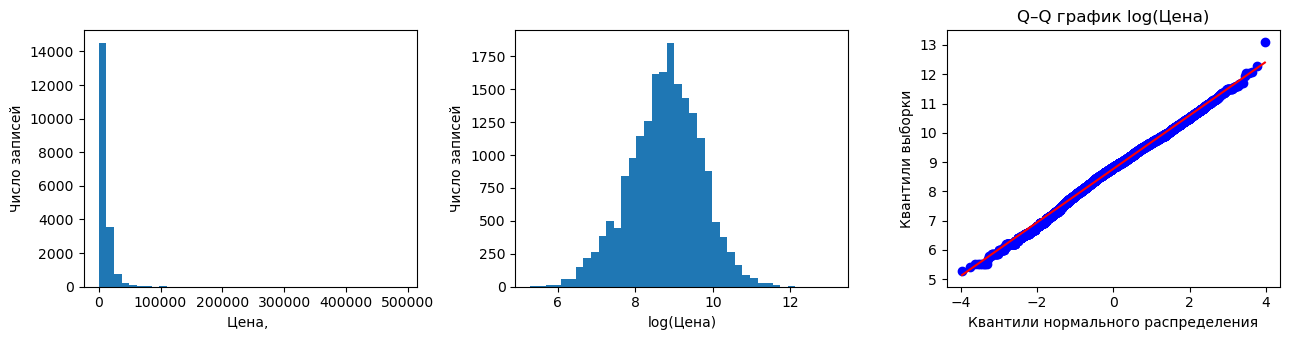

In [91]:
from scipy.stats import probplot

y_train_log = np.log(y_train)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(y_train, bins=40)
axes[0].set(xlabel='Цена, ', ylabel='Число записей')
axes[1].hist(y_train_log, bins=40)
axes[1].set(xlabel='log(Цена)', ylabel='Число записей')
probplot(y_train_log, dist='norm', plot=axes[2])
axes[2].set(title='Q–Q график log(Цена)', xlabel='Квантили нормального распределения',
            ylabel='Квантили выборки')
fig.tight_layout()
plt.show()

Распределение логарифма цены более симметрично. На Q–Q графике точки близки к прямой, но крайние значения отклоняются от неё.

Обучаем LR на тех же признаках OHE. Меняем только целевую переменную. Перед расчётом ошибки возвращаем прогноз в евро через `exp()`.

In [92]:
lr_log = LinearRegression()
lr_log.fit(train_ohe, y_train_log)
pred_log = lr_log.predict(test_ohe)
pred_price = np.exp(pred_log)

### Итоговая ошибка на test

Сравниваем все прогнозы в евро. MAE показывает средний модуль ошибки. RMSE сильнее реагирует на крупные ошибки. Сопоставляем LR на исходной цене и LR на логарифме на одних и тех же признаках.

In [114]:
test_predictions = {
    'CatBoost': pred_catboost,
    'LightGBM': pred_lightgbm,
    'LR + OHE + log(Price)': pred_price
}

In [115]:
test_results = pd.DataFrame([
    [name, mean_absolute_error(y_test, pred), root_mean_squared_error(y_test, pred)]
    for name, pred in test_predictions.items()
], columns=['Модель', 'MAE, ', 'RMSE, ']).sort_values('MAE, ')
display(test_results.round(2))

,Модель,"MAE,","RMSE,"
0,CatBoost,2053.92,5732.53
1,LightGBM,2132.52,5342.05
2,LR + OHE + log(Price),2146.27,5949.88


#### Упражнение
1. Проверьте `LR  + log(Price)` с `TargetEncoding`

2. Постройте интерактивные графики распределения цены и найдите выбросы. Проверьте как изменится точность для выборки без выбросов.

Сравните изменение MAE и RMSE после обучения LR на логарифме цены. Близкие значения MAE у двух моделей сами по себе не показывают, насколько устойчива разница.

### Как MAE и RMSE зависят от разбиения данных

Объединяем исходные train и validation. Для каждого `random_state` от 0 до 99 делим эти данные заново: 75% на обучение, 25% на проверку. Исходный test в эти повторы не входит.

На каждом новом train строим словари категорий и обучаем два RF: со всеми признаками и с сокращённым набором, выбранным выше. Для обоих RF используем одно и то же разбиение. `random_state` самого леса остаётся равным 42. Боксплоты показывают, как меняются ошибки на validation при смене разбиения. Цикл обучает 200 лесов и может занять несколько минут.

In [54]:
X_dev = pd.concat([X_train, X_valid])
y_dev = pd.concat([y_train, y_valid])
full = 'RF: все признаки'
reduced = 'RF: сокращённый набор'
feature_sets = {full: X_dev.columns.tolist(), reduced: reduced_cols}
split_rows = []

for seed in range(100):
    X_fit, X_eval, y_fit, y_eval = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=seed
    )
    X_fit, X_eval = encode_for_rf(X_fit, X_eval, threshold=0)
    for name, cols in feature_sets.items():
        model = RandomForestRegressor(**rf_params)
        model.fit(X_fit[cols], y_fit)
        pred = model.predict(X_eval[cols])
        split_rows.append([seed, name, mean_absolute_error(y_eval, pred),
                           root_mean_squared_error(y_eval, pred)])

split_results = pd.DataFrame(split_rows, columns=['random_state', 'Модель', 'MAE', 'RMSE'])
mae_runs = split_results.pivot(index='random_state', columns='Модель', values='MAE')
rmse_runs = split_results.pivot(index='random_state', columns='Модель', values='RMSE')

NameError: name 'encode_for_rf' is not defined

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, runs, name in zip(axes, [mae_runs, rmse_runs], ['MAE', 'RMSE']):
    runs.plot.box(ax=ax, vert=False)
    ax.set(xlabel=f'{name}, евро', title=f'{name} на validation: 100 разбиений')
fig.tight_layout()
plt.show()

In [ ]:
abs_errors = pd.DataFrame({
    name: np.abs(y_test.to_numpy() - pred)
    for name, pred in test_predictions.items()
})[test_results['Модель']]
ax = abs_errors.plot.box(vert=False, showfliers=False, figsize=(10, 5))
ax.set_xlabel('Абсолютная ошибка, евро')
ax.set_title('Распределение ошибок по записям на полном test')
plt.tight_layout()
plt.show()

### Распределение остатков

Регрессия не меняет распределение цен в исходных данных. Отдельно от распределения цели проверим **остатки** — разности между фактическим значением и прогнозом в шкале обучения. На Q–Q графике близость точек к прямой указывает на близость к нормальному распределению. Систематические отклонения, особенно в хвостах, указывают на различия.

KeyError: 'LR + OHE'

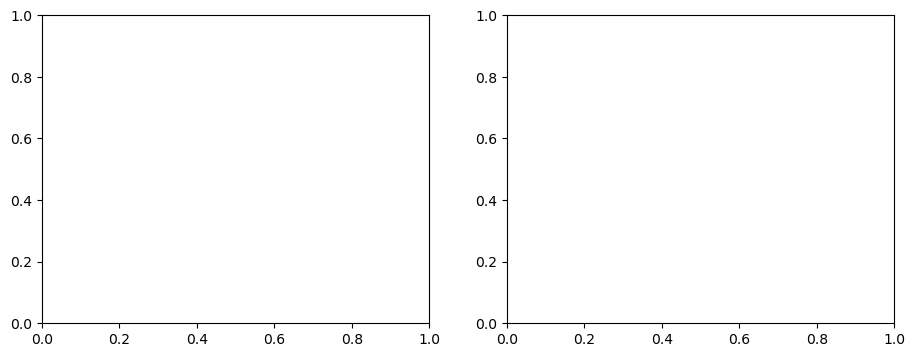

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
probplot(y_test - test_predictions['LR + OHE'], dist='norm', plot=axes[0])
probplot(np.log(y_test) - pred_log, dist='norm', plot=axes[1])
axes[0].set(title='Остатки LR в евро', xlabel='Нормальные квантили', ylabel='Квантили остатков')
axes[1].set(title='Остатки LR в лог-шкале', xlabel='Нормальные квантили', ylabel='Квантили остатков')
fig.tight_layout()
plt.show()

У обеих моделей точки в хвостах заметно отклоняются от прямой. Логарифмирование цены не сделало распределение остатков нормальным.

**Задание.** На сколько евро изменились MAE и RMSE после логарифмирования? Сравните результат с обоими бустингами. На каком Q–Q графике точки ближе к прямой?